# Autoencoder: MNIST Reconstruction

Compress a digit to 16 latent coordinates and reconstruct its pixels. Training uses 55,000 images; validation and test use the same MNIST split conventions as the classifier.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxlib as nj
from neuraljaxlib import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery-refined/autoencoder'
print(f"NeuralJAXlib {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXlib 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

Flattened input has 784 features. The encoder/decoder use width 256, a 16-dimensional bottleneck, and sigmoid reconstruction in `[0,1]`. MSE averages over pixels.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.Autoencoder), language="python"))

class Autoencoder(nn.Module):
    """MNIST autoencoder with named reconstruction and latent outputs."""

    def __init__(self, latent_size=16, width=128, *, rngs):
        super().__init__()
        self.encoder = MLP(784, [width], latent_size, rngs=rngs)
        self.decoder = MLP(latent_size, [width], 784, rngs=rngs)

    def encode(self, images):
        return self.encoder(images.reshape(images.shape[0], 784))

    def decode(self, latent):
        return F.sigmoid(self.decoder(latent)).reshape(-1, 1, 28, 28)

    def forward(self, images):
        z = self.encode(images)
        return {"reconstruction": self.decode(z), "latent": z}

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [3]:
display(Code(inspect.getsource(training.autoencoder_step), language="python"))

@jit
def autoencoder_step(model, optimizer, images):
    loss, grads = value_and_grad(lambda m: F.mse_loss(m(images)["reconstruction"], images))(model)
    optimizer.step(grads)
    return {"loss": loss, "count": images.shape[0]}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'autoencoder', '--download',
           '--output', str(RUN), *RECIPES['autoencoder']]
print(' '.join(part.replace(str(ROOT) + '/', '')
               for part in ['python', *command[1:]]))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

python -m examples.run autoencoder --download --output runs/gallery-refined/autoencoder --epochs 25 --limit 55000 --eval-limit 10000 --batch-size 256


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,25,256,0,55000,5000,10000


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

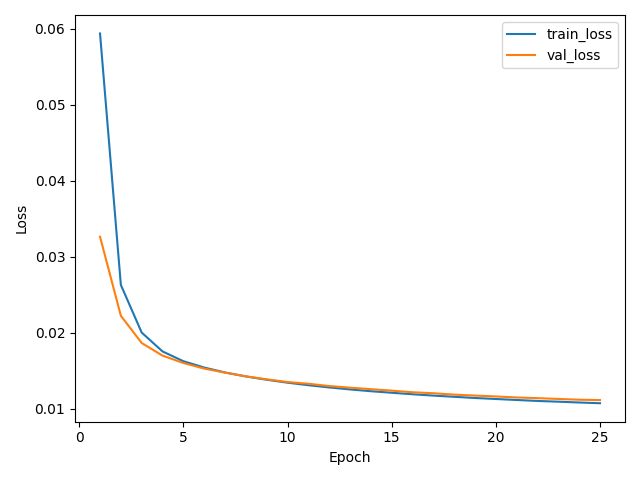

Selected epoch: 25


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

Original/reconstruction pairs show which strokes survive compression. The latent PCA plot uses held-out labels only for coloring, not training; its appearance is not evidence of disentanglement. Pixel MSE is not classification accuracy.

In [6]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

,Metric,Value
0,test_loss,0.010804


Timed training loop (including validation/checkpoint work): 15.18 seconds


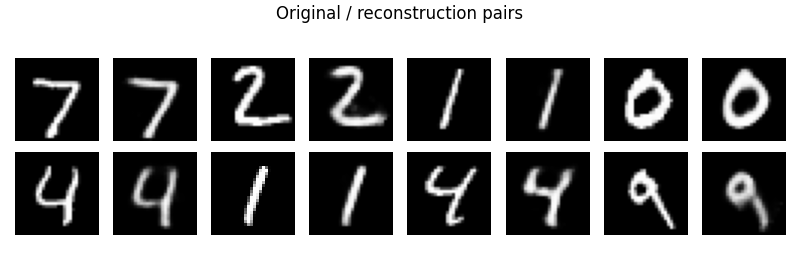

In [7]:
display(Image(filename=str(RUN / 'reconstructions.png')))

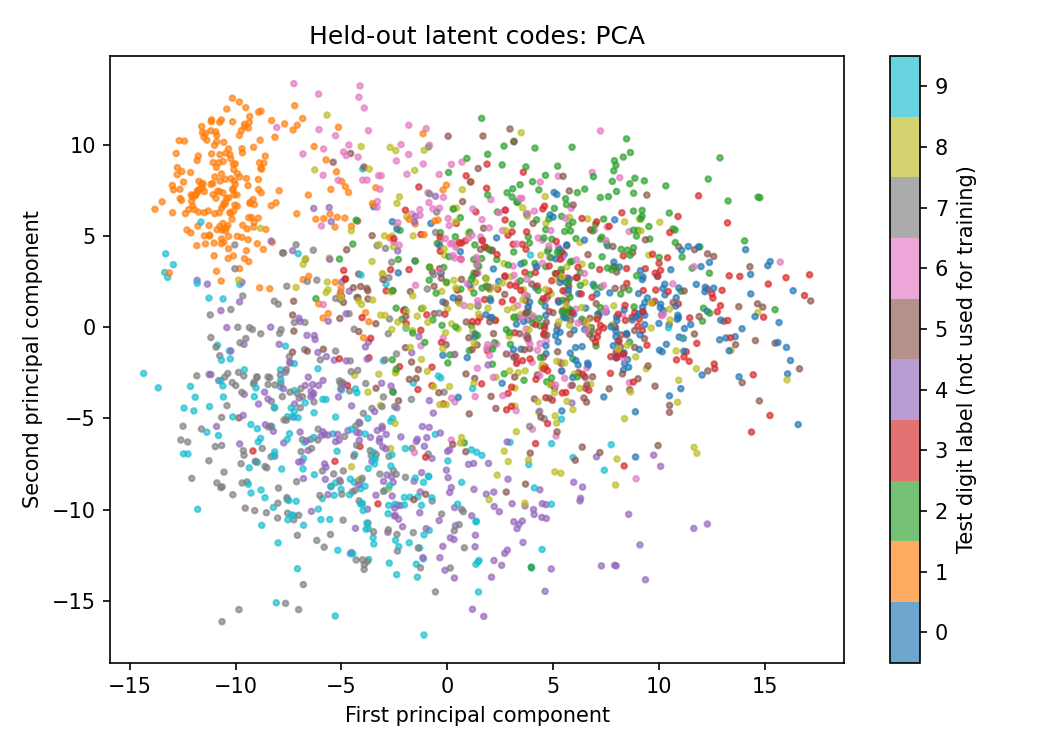

In [8]:
display(Image(filename=str(RUN / 'latent.png')))

## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.